# Dati e frequenze
Vedremo come esistano tipi differenti di dati, e come in funzione del loro tipo esistano diversi strumenti grafici che li descrivono. Studieremo inoltre in modo più approfondito e diversificato il concetto di _frequenza_.

Come sempre, carichiamo le librerie e il dataset dei supereroi. Già che ci siamo, escludiamo l'unico record che fa riferimento al 2099 come anno di prima apparizione.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import golden

#plt.style.use('fivethirtyeight')
plt.rc('figure', figsize=(5.0, 5.0/golden))

heroes = pd.read_csv('data/heroes.csv', sep=';', index_col=0)
heroes_with_year = heroes[heroes['First appearance'] < 2020]

heroes_with_year.head()

,Identity,Birth place,Publisher,Height,Weight,Gender,First appearance,Eye color,Hair color,Strength,Intelligence
Name,,,,,,,,,,,
A-Bomb,Richard Milhouse Jones,"Scarsdale, Arizona",Marvel Comics,203.21,441.95,M,2008.0,Yellow,No Hair,100.0,moderate
Agent Bob,Bob,NaN,Marvel Comics,178.25,81.45,M,2007.0,Brown,Brown,10.0,low
Abe Sapien,Abraham Sapien,NaN,Dark Horse Comics,191.24,65.35,M,1993.0,Blue,No Hair,30.0,high
Abin Sur,NaN,Ungara,DC Comics,185.52,90.90,M,1959.0,Blue,No Hair,90.0,average
Animal Man,Bernhard Baker,NaN,DC Comics,183.80,83.39,M,1965.0,Blue,Blond,50.0,average


## Dati quantitativi e qualitativi
Una delle principali distinzioni che si possono fare sui dati osservabili riguarda il modo in cui questi sono misurati:
- si parla di dati _quantitativi_ se l'esito della misurazione è una quantità numerica;
- si parla invece di dati _qualitativi_ (o categorici, o nominali) quando la misurazione è fatta scegliendo un'etichetta a partire da un insieme disponibili.

Pertanto nel nostro dataset i caratteri _Height_, _Weight_ e _Strength_ saranno da considerare quantitativi, mentre i caratteri _Name_, _Identity_, _Birth place_, _Publisher_, _Gender_, _Eye color_, _Hair color_ e _Intelligence_ saranno sicuramente di tipo qualitativo (la differenza tra _Strength_ e _Intelligence_ è legata al fatto che il primo carattere è misurato tramite numeri che variano tra 0 e 100 mentre il secondo fa riferimento a una scala basata su etichette). La classificazione di _First appearance_ è più sfumata e merita qualche riflessione in più: sebbene l'anno di prima apparizione sia misurato tramite un numero intero, il suo valore non indica prettamente una _quantità_, bensì _quando_ è accaduto un evento. In tal senso, il calcolo di operazioni aritmetiche quali la somma o la divisione perde di significato, ed è per questo che spesso caratteri di questo tipo ricadono nella classe dei dati qualitativi. Cionondimeno, vedremo come sia possibile ragionare sul carattere _First appearance_ anche in termini quantitativi quando per esempio parleremo della visualizzazione di istogrammi. Ci sono poi casi di caratteri espressi in termini temporali in cui viene misurato il tempo intercorso a partire da un dato istante iniziale (come per esempio il tempo di arrivo del primo cliente in un negozio, misurato in minuti dall'orario di apertura), di cui è chiara l'appartenenza alla classe dei dati quantitativi.

### Classificazione dei dati qualitativi
I dati qualitativi vengono spesso ulteriormente classificati come binari/booleani, nominali oppure ordinali. Si parla di dati _binari_ o _booleani_ quando l'osservazione può avere solo due esiti tra loro non confrontabili (volendo si può parlare di dati booleani per enfatizzare che si sta valutando la presenza o l'assenza di una proprietà, e di dati binari quando esistono due possibili etichette): in tal senso, il carattere _Gender_, che può assumere solo i valori M e F, è quindi un carattere qualitativo binario. Anche nei dati _nominali_ (detti anche sconnessi), di cui i dati binari rappresentano un caso particolare, i valori osservabili non sono tra loro confrontabili, sebbene non vi sia limite sul numero di diverse etichette. Saranno dunque dati qualitativi nominali, oltre al già considerato _Gender_, anche _Name_, _Identity_, _Birth place_, _Publisher_, _Eye color_ e _Hair color_. Detto in altri termini, in questo tipo di dati (e quindi anche nel caso binario/booleano) è solo possibile stabilire una relazione di equivalenza tra i valori osservabili: pertanto, due osservazioni potranno avere valori uguali oppure diversi, e nulla più si potrà dire sul loro rapporto. Nei dati _ordinali_, invece, è possibile stabilire una relazione d'ordine tra i valori osservabili, e quindi quando due valori saranno diversi sarà anche possibile dire quale tra i due sia il più piccolo e quale il più grande. Nel nostro dataset, solo _Intelligence_ è un dato qualitativo ordinale.

### Classificazione dei dati quantitativi
Per quanto riguarda i dati quantitativi, viene spesso fatto riferimento alla differenza tra dati _discreti_ e _continui_ in funzione del tipo di insieme di valori che questi possono assumere. Va in realtà notato che i dati che elaboriamo sono memorizzati su un computer e quindi i valori reali vengono approssimati tramite valori all'interno di un insieme finito (dunque discreto). Vale più la pena ragionare in termini di caratteri per cui ha senso dare significato a un singolo valore (come nel caso dell'anno di prima apparizione, in cui ha senso considerare gli eroi apparsi nel 1970) e di caratteri in cui di norma ha senso considerare un _intervallo_ di valori (come nel caso dei rimanenti caratteri: ha di solito poco senso considerare, per esempio, un eroe alto esattamente 178 centimetri o con un indice di forza pari a 42).

In alcuni casi si considerano diversi i caratteri quantitativi in funzione che abbia o meno senso considerare il _rapporto_ tra i corrispondenti valori: sarebbe questo il caso dei caratteri _Height_, _Weight_ e _Strength_ nel nostro dataset.

## Frequenze assolute e relative e loro visualizzazione
Abbiamo già incontrato il concetto di _frequenza assoluta_: si tratta del conteggio del numero di volte che una data osservazione occorre in un campione. Questo tipo di informazione è facilmente analizzabile quando il numero di differenti osservazioni non è troppo grande: ciò accade quasi sempre quando si analizzano caratteri qualitativi e relativamente meno spesso per i caratteri quantitativi. Prendiamo per esempio in considerazione il carattere _Publisher_, e calcoliamone le frequenze assolute usando il già introdotto metodo `value_counts`

In [2]:
heroes_with_year['Publisher'].value_counts()

Publisher
Marvel Comics        205
DC Comics            121
Dark Horse Comics     12
George Lucas          11
ABC Studios            4
Image Comics           3
Rebellion              1
Star Trek              1
Universal Studios      1
Hanna-Barbera          1
Name: count, dtype: int64

Vi sono dunque, nel dataset che stiamo analizzando, dieci diversi valori possibili per l'editore: ciò rende l'insieme delle frequenze assolute facilmente visualizzabile in forma tabulare, costruendo la cosiddetta _tabella delle frequenze assolute_ in cui si ha una riga per ogni possibile valore osservabile, e tale riga contiene il valore stesso e la corrispondente frequenza assoluta. In senso lato, già l'output di `value_counts` è una tabella delle frequenze assolute, anche se è possibile utilizzare la funzione `pd.crosstab` per ottenere una visualizzazione più elegante, in quanto tale funzione restituisce un _dataframe_:

In [3]:
publisher_freq = pd.crosstab(index=heroes_with_year['Publisher'],
                             columns=['Abs. frequence'],
                             colnames=[''])
publisher_freq

,Abs. frequence
Publisher,
ABC Studios,4
DC Comics,121
Dark Horse Comics,12
George Lucas,11
Hanna-Barbera,1
Image Comics,3
Marvel Comics,205
Rebellion,1
Star Trek,1


<div class="alert alert-info">
    L'argomento essenziale di <code>pd.crosstab</code> è, in questo caso, <code>index</code>, che viene impostato alla serie di cui vanno calcolate le frequenze assolute; i due rimanenti argomenti influiscono solo sul modo in cui viene visualizzata la tabella delle frequenze: <code>columns</code> contiene una lista il cui unico elemento è l'intestazione della colonna delle frequenze, mentre <code>colnames</code> viene impostato a una lista contenente una stringa vuota al fine di non visualizzare un'ulteriore etichetta per l'intera tabella.
</div>

Essendo l'output di `pd.crosstab` un _dataframe_, su esso si possono eseguire operazioni quali _slicing_, accesso basato su indice e su posizione e così via. Ciò permette di trasformare facilmente una tabella di frequenze assolute nella corrispondente tabella delle _frequenze relative_, dove la frequenza relativa di un'osservazione è la frazione di casi in quell'osservazione occorre. L'uso delle frequenze relative permette di valutare più facilmente la grandezza dei valori in gioco, in quanto questi varieranno sempre tra 0 e 1, mentre le frequenze assolute non hanno a priori un valore massimo e quindi è meno facile valutare se una frequenza è alta o bassa. Le frequenze relative si calcolano dividendo quelle assolute per il numero totale di casi; quest'ultimo è ovviamente uguale alla somma di tutte le frequenze assolute, quindi la tabella delle frequenze relative si può ottenere nel modo seguente:

In [4]:
publisher_abs_freq = pd.crosstab(index=heroes_with_year['Publisher'],
                                 columns=['Rel. frequence'],
                                 colnames=[''])
publisher_rel_freq = publisher_abs_freq / publisher_abs_freq.sum()

publisher_rel_freq

,Rel. frequence
Publisher,
ABC Studios,0.011111
DC Comics,0.336111
Dark Horse Comics,0.033333
George Lucas,0.030556
Hanna-Barbera,0.002778
Image Comics,0.008333
Marvel Comics,0.569444
Rebellion,0.002778
Star Trek,0.002778


In realtà è possibile creare direttamente la tabella delle frequenze relative specificando il valore `True` per l'argomento `normalize`:

In [5]:
publisher_rel_freq = pd.crosstab(index=heroes_with_year['Publisher'],
                                 columns=['Rel. frequence'],
                                 colnames=[''],
                                 normalize=True)
publisher_rel_freq

,Rel. frequence
Publisher,
ABC Studios,0.011111
DC Comics,0.336111
Dark Horse Comics,0.033333
George Lucas,0.030556
Hanna-Barbera,0.002778
Image Comics,0.008333
Marvel Comics,0.569444
Rebellion,0.002778
Star Trek,0.002778


La visualizzazione della tabella può essere migliorata riducendo il numero di cifre visualizzate, applicando ai suoi elementi la funzione `np.round` che arrotonda un valore floating point mantenendo un numero prefissato di cifre decimali:

In [6]:
publisher_rel_freq.apply(lambda p: 100 * np.round(p, 3))

,Rel. frequence
Publisher,
ABC Studios,1.1
DC Comics,33.6
Dark Horse Comics,3.3
George Lucas,3.1
Hanna-Barbera,0.3
Image Comics,0.8
Marvel Comics,56.9
Rebellion,0.3
Star Trek,0.3


Volendo visualizzare la frequenza relativa usando delle percentuali è possibile operare in modo simile: basta moltiplicare per 100 i valori una volta che questi sono stati arrotondati in modo da tener conto delle cifre decimali che si vogliono visualizzare. Nella cella seguente il risultato viene convertito in una serie di stringhe, così da poter effettuare un'ultima trasformazione che visualizza le percentuali utilizzando il simbolo `%`:

In [7]:
(publisher_rel_freq.apply(lambda p: np.round(100*p, 2)).astype(str).apply(lambda s: s + '%'))

,Rel. frequence
Publisher,
ABC Studios,1.11%
DC Comics,33.61%
Dark Horse Comics,3.33%
George Lucas,3.06%
Hanna-Barbera,0.28%
Image Comics,0.83%
Marvel Comics,56.94%
Rebellion,0.28%
Star Trek,0.28%


L'ordine delle righe in una tabella delle frequenze è quello individuato dal suo indice, che tipicamente è legato all'ordinamento predefinito (non decrescente) dei suoi elementi: nel caso di stringhe, quindi, le righe saranno ordinate alfabeticamente per i valori della prima colonna.

In [8]:
gender_freq = pd.crosstab(index=heroes_with_year['Gender'],
                          columns=['Abs. frequence'],
                          colnames=[''])
gender_freq

,Abs. frequence
Gender,
F,87
M,272


Volendo modificare tale ordine è possibile accedere al _dataframe_ corrispondente alla tabella tramite `loc` e specificando come secondo argomento una lista dei valori nell'ordine desiderato:

In [9]:
gender_freq.loc[['M', 'F']]

,Abs. frequence
Gender,
M,272
F,87


Abbiamo già visto come utilizzando l'attributo `plot` di una serie sia possibile visualizzarne graficamente i contenuti. In particolare, per i dati di tipo qualitativo è tipicamente sensato utilizzare i grafici a barre:

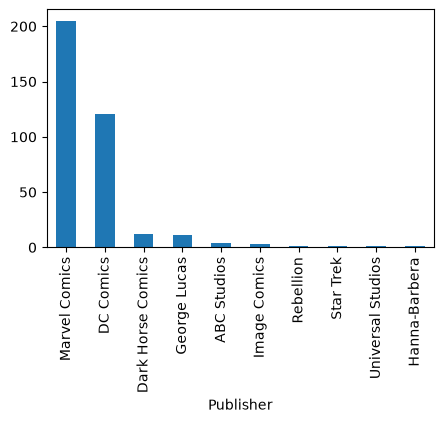

In [10]:
heroes_with_year['Publisher'].value_counts().plot.bar()
plt.show()

Un grafico analogo si ottiene invocando sempre il metodo `plot.bar` sul _dataframe_ corrispondente alla tabella delle frequenze:

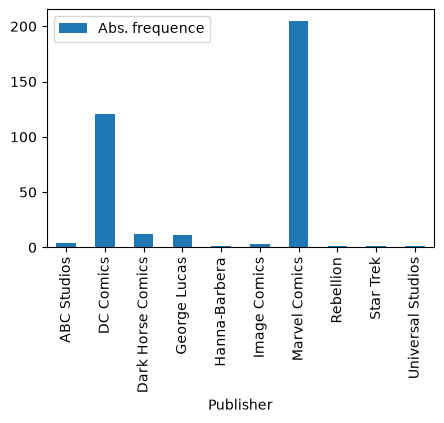

In [11]:
publisher_freq.plot.bar()
plt.show()

Vi sono due principali differenze tra i grafici a barre ottenuti:
- nel primo le barre sono ordinate per frequenza non crescente, mentre nel secondo queste seguono l'ordinamento (in questo caso alfabetico) dei corrispondenti valori;
- il secondo grafico contiene una legenda ed etichetta l'asse delle ascisse con il nome del carattere considerato.

Volendo eliminare la legenda è sufficiente rigenerare il grafico specificando il valore `False` per l'argomento `legend`:

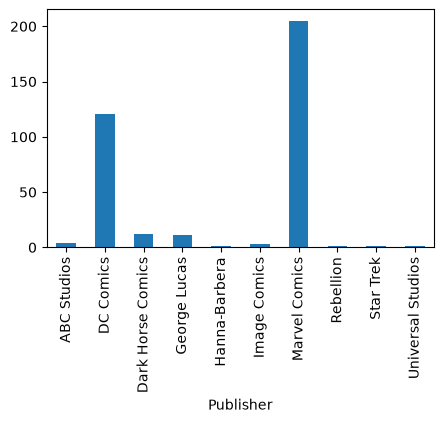

In [12]:
publisher_freq.plot.bar(legend=False)
plt.show()

Volendo visualizzare le barre in un ordine differente è sufficiente riordinare il _dataframe_ nello stesso modo già visto per le tabelle delle frequenze, prima di invocare `plt.plot`.

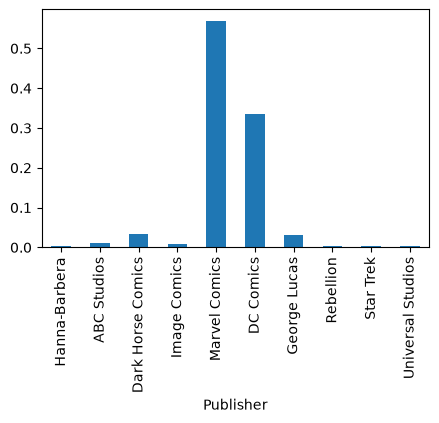

In [13]:
publisher_order = ['Hanna-Barbera', 'ABC Studios', 'Dark Horse Comics',
                   'Image Comics', 'Marvel Comics', 'DC Comics',
                   'George Lucas', 'Rebellion',
                   'Star Trek', 'Universal Studios']

publisher_rel_freq.loc[publisher_order,:].plot.bar(legend=False)
plt.show()

Oltre a modificare l'ordine delle barre, il grafico precedente visualizza le frequenze relative, ottenute in questo caso facendo riferimento alla tabella `publisher_rel_freq` precedentemente generata.
Ovviamente il grafico che si ottiene è analogo a quello delle frequenze assolute: l'unica cosa che cambia è la scala di valori sull'asse delle ascisse.

L'uso delle frequenze relative permette anche di confrontare situazioni in cui il numero di osservazioni è variabile. Se per esempio volessimo comparare le frequenze della forza dei supereroi con quelle delle supereroine, ci troveremmo con due diversi numeri di osservazioni:

In [14]:
male_strength_freq = pd.crosstab(index=heroes.loc[heroes['Gender']=='M', 'Strength'],
                                 columns='Abs. freq.')
female_strength_freq = pd.crosstab(index=heroes.loc[heroes['Gender']=='F', 'Strength'],
                                   columns='Abs. freq.')

num_male = sum(male_strength_freq['Abs. freq.'])
num_female = sum(female_strength_freq['Abs. freq.'])

print('Ci sono {} supereroi e {} supereroine'.format(num_male, num_female))

Ci sono 428 supereroi e 164 supereroine


Sovrapporre quindi i grafici a barre delle frequenze assolute non avrebbe senso, perchè le relative altezze non sarebbero confrontabili. Ha invece senso fare il confronto con le frequenze relative. Già che ci siamo, utilizziamo l'argomento `color` per impostare rispettivamente a blu e rosa i colori dei settori che corrispondono a maschi e femmine.

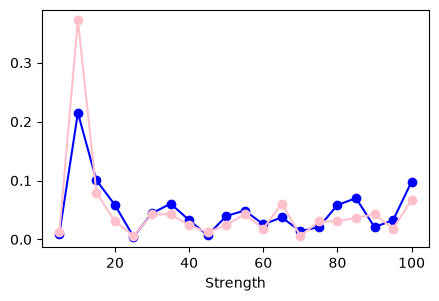

In [15]:
male_strength_freq = (pd.crosstab(index=heroes.loc[heroes['Gender']=='M', 'Strength'],
                                  columns='Rel. freq.',
                                  normalize=True).loc[:, 'Rel. freq.'])
male_strength_freq = male_strength_freq.reindex(heroes['Strength'].unique()).dropna().sort_index()

female_strength_freq = (pd.crosstab(index=heroes.loc[heroes['Gender']=='F', 'Strength'],
                                    columns='Rel. freq.',
                                    normalize=True).loc[:, 'Rel. freq.'])
female_strength_freq = female_strength_freq.reindex(heroes['Strength'].unique()).dropna().sort_index()

male_strength_freq.plot(marker='o', color='blue', legend=False)
female_strength_freq.plot(marker='o', color='pink', legend=False)
plt.show()

<div class="alert alert-warning">
    Se siete stati attenti avrete notato che le tabelle delle frequenze sono state accedute tramite <code>loc</code> al fine di estrarre le corrispondenti serie. Ciò è dovuto al fatto che in caso contrario matplotlib avrebbe prodotto due grafici separati.
</div>

In effetti la cella precedente non genera un vero e proprio grafico a barre, perchè per ogni valore della forza ci sarebbero due barre, relative ai due generi. Tali barre si sovrapporrebbero, con l'effetto di nascondere (parzialmente o totalmente) quella più bassa.

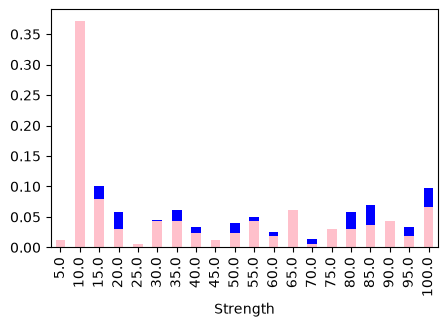

In [16]:
male_strength_freq.plot.bar(color='blue', legend=False)
female_strength_freq.plot.bar(color='pink', legend=False)
plt.show()

Un'alternativa è quella di specificare il parametro `alpha` nelle funzioni che generano i grafici: ciò permette di disegnare delle barre semi-trasparenti che evidenziano le loro sovrapposizioni.

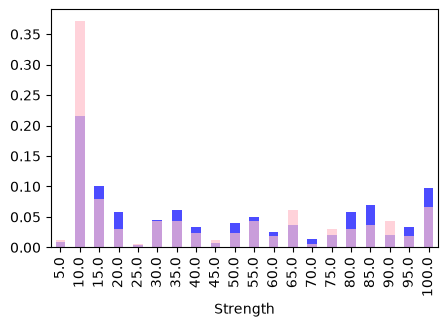

In [17]:
male_strength_freq.plot.bar(color='blue', alpha=.7)
female_strength_freq.plot.bar(color='pink', alpha=.7)
plt.show()

Una modalità alternativa per visualizzare le frequenze in caso di valori qualitativi, evidenziando inoltre le frazioni rispetto al numero totale dei casi è quella di utilizzare il metodo `pie` per produrre un diagramma a torta, o più tecnicamente un _aerogramma_, in cui un cerchio è diviso in tanti settori le cui aree sono proporzionali alle frequenze (pertanto il grafico ottenuto sarà indipendente dall'avere considerato le frequenze assolute oppure quelle relative). Per esempio, la cella seguente calcola il diagramma a torta delle frequenze relative al genere dei supereroi.

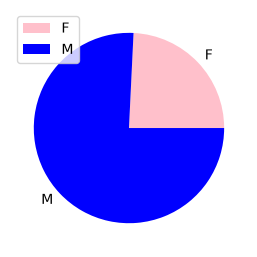

In [18]:
gender_freq.plot.pie(y='Abs. frequence', colors=['pink', 'blue'])
plt.show()

Ci sono alcune cose che vale la pena sottolineare.
- A differenza dei grafici generati fino a ora, qui è stato necessario specificare il nome della colonna nel _dataframe_ corrispondente alla tabella delle frequenze. Ciò è legato al fatto che mentre metodi come `plot.bar` sono in grado di visualizzare più caratteri contemporaneamente, quando si disegna un diagramma a torta è necessario utilizzare un solo carattere e quindi è necessario selezionarlo nel dataframe, anche in casi come questo in cui vi è effettivamente un solo carattere; in alternativa, è possibile estrarre la serie dal _dataframe_ e invocare su di essa `plot.pie`: in altre parole l'istruzione seguente avrebbe generato un grafico analogo:
```
gender_freq['Abs. frequence'].plot.pie(colors=['pink', 'blue'])
```
- Mentre quando si crea un grafico a barre per un carattere ha ampiamente senso utilizzare lo stesso colore per tutte le barre, nel caso di un diagramma a torta tale scelta renderebbe il risultato illeggibile, ed è per questo che se si vogliono personalizzare i colori è necessario passare la lista dei corrispondenti nomi all'argomento `colors` (che è diverso dall'argomento `color` finora utilizzato).

Consideriamo il caso particolare dell'anno di apparizione: se ne tracciamo il grafico a barre delle frequenze assolute, è appropriato posizionare le barre rispettando la relazione di ordine esistente tra i dati, utilizzando direttamente matplotlib come abbiamo visto nella lezione precedente.

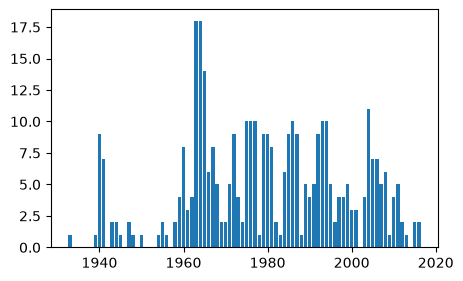

In [19]:
first_app_freq = heroes_with_year['First appearance'].value_counts()
plt.bar(first_app_freq.index, first_app_freq.values)
plt.show()

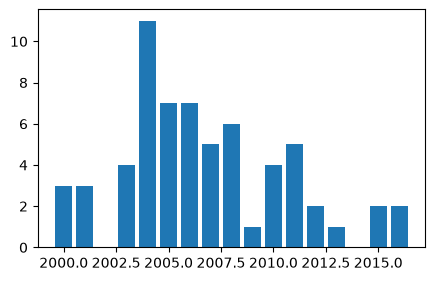

In [20]:
selected_freq = first_app_freq[first_app_freq.index >= 2000]
plt.bar(selected_freq.index, selected_freq.values)
plt.show()

Il risultato non è però ottimale perchè le barre hanno uno spessore (sebbene in questo caso sia molto piccolo, a causa dell'elevato numero di barre) che può suggerire un'interpretazione fuorviante del grafico, secondo cui le frequenze non facciano riferimento a un anno, bensì a un intervallo temporale centrato in un anno. Per evitare tale fraintendimento è più appropriato in casi come questo produrre un grafico _a bastoncini_ in cui ogni punto è evidenziato, piuttosto che da una barra, da un segmento verticale che lo congiunge con l'asse delle ascisse (cosa che, peraltro, permette di non scambiare per nulle le frequenze relativamente basse):

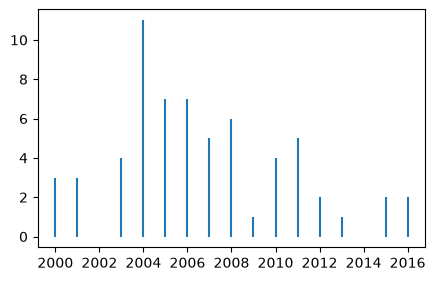

In [21]:
plt.vlines(selected_freq.index, 0, selected_freq.values)
plt.show()

È anche possibile abbinare ogni segmento a un cerchio centrato sul punto che identifica un valore e la sua frequenza: basta generare il grafico precedente e sovrapporgli i singoli punti.

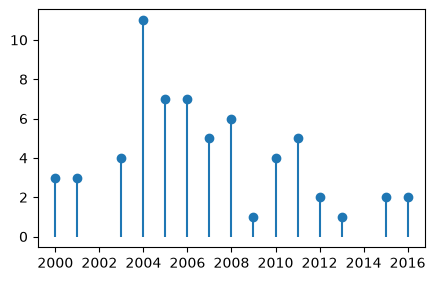

In [22]:
plt.vlines(selected_freq.index, 0, selected_freq.values)
plt.plot(selected_freq.index, selected_freq.values, 'o')
plt.show()

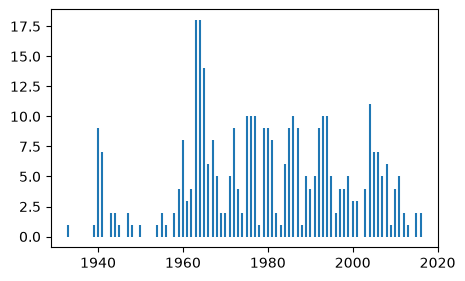

In [23]:
plt.vlines(first_app_freq.index, 0, first_app_freq.values)
plt.show()

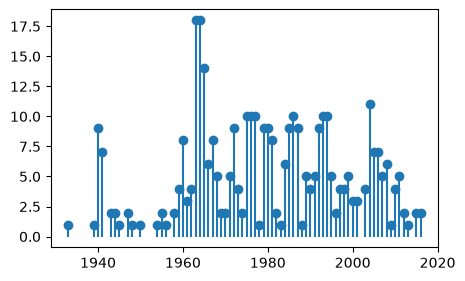

In [24]:
plt.vlines(first_app_freq.index, 0, first_app_freq.values)
plt.plot(first_app_freq.index, first_app_freq.values, 'o')
plt.show()

Infine, consideriamo il diagramma a bastoncini relativo al peso dei supereroi.

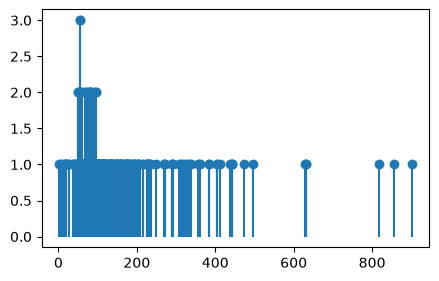

In [25]:
weight_freq = heroes['Weight'].value_counts()

plt.vlines(weight_freq.index, 0, weight_freq.values)
plt.plot(weight_freq.index, weight_freq.values, 'o')
plt.show()

In [26]:
heroes['Weight']

Name
A-Bomb         441.95
Abraxas           NaN
Abomination    441.98
Adam Monroe       NaN
Agent 13        61.03
                ...  
Alan Scott      90.81
Amazo          173.95
Ant-Man        122.44
Ajax            90.63
Alex Mercer       NaN
Name: Weight, Length: 735, dtype: float64

Due pesi, per dire, di 81.12 kg e di 81.14 kg vengono considerati in questo grafico come due valori differenti, ed è per questo che vi sono quasi esclusivamente bastoncini di altezza unitaria: quasi tutti i valori occorrono praticamente un'uncia volta nel dataset. Ciò è dovuto al fatto che il peso è un dato quantitativo per cui non ha di norma senso considerare un singolo valore, e risulta più sensato calcolare le frequenze di _intervalli_ di possibili valori osservabili. Il grafico corrispondente prende il nome di _istogramma_, e viene calcolato e visualizzato in pandas invocando il metodo `hist` sulla serie corrispondente:

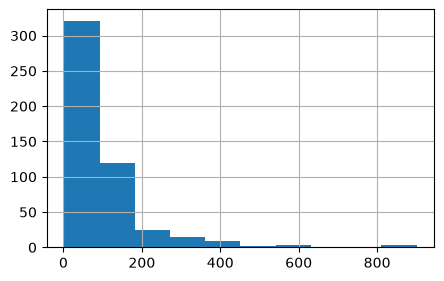

In [27]:
heroes['Weight'].hist()
plt.show()

Ovviamente il risultato ottenuto dipende da come sono stati scelti gli intervalli su cui calcolare le frequenze. Di norma si divide l'intervallo che contiene tutti i dati osservati in sotto-intervalli equiampi, il cui numero è individuato dall'argomento `bins`.

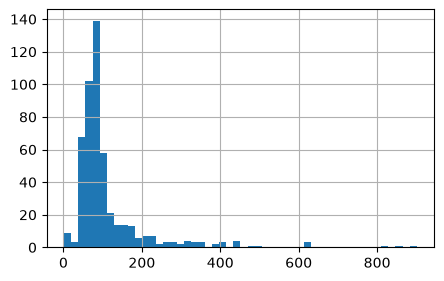

In [28]:
heroes['Weight'].hist(bins=50)
plt.show()

Questo istogramma ci dice, a occhio, che i pesi variano perlopiù tra zero e duecento chilogrammi, sebbene esistano errori con pesi maggiori. In teoria è possibile utilizzare sotto-intervalli di ampiezze differenti: per esempio, ampiezze pari a 20 per i pesi inferiori a 200 kg, pari a 50 per pesi compresi tra 200 e 500 kg, e pari a 100 per i valori rimanenti.

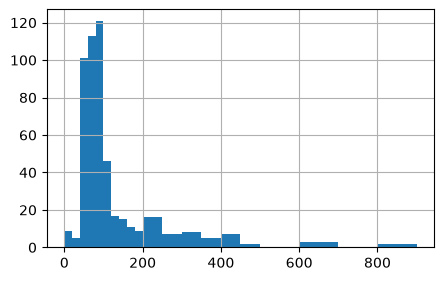

In [29]:
heroes['Weight'].hist(bins=np.hstack((np.arange(0, 200, 20),
                                      np.arange(200, 500, 50),
                                      np.arange(500, 1000, 100))))
plt.show()

Va notato come in questo caso le altezze delle barre non continuo il numero di occorrenze nel corrispondente intervallo: per esempio, vi sono tre pesi superiori a 800 kg, ma la barra corrispondente ha altezza unitaria. Ciò è dovuto al fatto che in un istogramma è l'_area_ di ogni barra a essere legata alla frequenza: se le barre hanno basi della stessa lunghezza, le aree sono proporzionali all'altezza, altrimenti no. È per questo, per esempio, che le due barre più a destra nell'ultimo istogramma hanno altezza unitaria: si riferiscono a tre osservazioni, e la loro area è il triplo dell'area di una barra di altezza unitaria nella parte sinistra del grafico, che invece farebbe riferimento a una sola osservazione.

<div class="alert alert-info">
    Nella cella precedente sono state utilizzate le funzioni <code>np.hstack</code>, che permette di giustapporre due o più array numpy, e <code>np.arange</code>, che crea un array i cui contenuti variano tra i valori indicati dai primi due argomenti, con incremento pari all'ultimo argomento.
</div>

## Frequenze cumulate
Riconsideriamo l'anno di prima apparizione dei supereroi, e rispondiamo alle domande che seguono.
1. Qual è il più recente tra gli anni di apparizione di un supereroe?
2. E qual è il meno recente?
3. Quanti supereroi hanno un anno di apparizione non superiore al 1970?
4. Quanti hanno un anno di apparizione successivo al 1980?

Per rispondere alle prime due domande basta selezionare la serie che corrisponde al carattere `first_appearance` e calcolarne il minimo e il massimo valore:

In [30]:
(heroes_with_year['First appearance'].min(), heroes_with_year['First appearance'].max())

(np.float64(1933.0), np.float64(2016.0))

Per rispondere invece alle rimanenti domande potremmo estrarre tramite una _list comprehension_ tutti gli anni in `heroes_with_year` che soddisfano i criteri indicati e calcolarne la lunghezza. Vale però la pena approfittarne per introdurre un nuovo strumento, che si rivelerà molto versatile: si tratta delle _frequenze cumulate_, che si possono calcolare quando esiste una relazione di ordine per i valori del carattere.
Essenzialmente si tratta di considerare i valori del carattere dal più piccolo al più grande, di calcolare le relative frequenze e di cumularle in modo che al primo elemento sia associata la sua frequenza, al secondo la somma delle frequenze dei primi due elementi, al terzo la somma delle prime tre frequenze e così via.

Per calcolarne le frequenze cumulate, pandas mette a disposizione il metodo `cumsum` per gli oggetti di tipo serie e _dataframe_. Quando viene utilizzato sulla serie prodotta da `value_counts` è però necessario riordinare le frequenze prodotte rispetto al loro indice e infine si può invocare il metodo. Risulta invece più comoco calcolare e generare il _dataframe_ corrispondente alla tabella delle frequenze, che risulta già ordinato nel modo corretto, e su questo invocare _cumsum_.

In [31]:
first_app_freq_cumulate = (pd.crosstab(index=heroes_with_year['First appearance'],
                                       columns=['Cumulate freq.'],
                                       colnames=[''])
                           .cumsum())
first_app_freq_cumulate.iloc[:10]

,Cumulate freq.
First appearance,
1933.0,1
1939.0,2
1940.0,11
1941.0,18
1943.0,20
1944.0,22
1945.0,23
1947.0,25
1948.0,26


Il grafico corrispondente mette in evidenza il fatto che le frequenze cumulate sono monotone crescenti e variano da 0 al numero totale di casi nel dataset considerato:

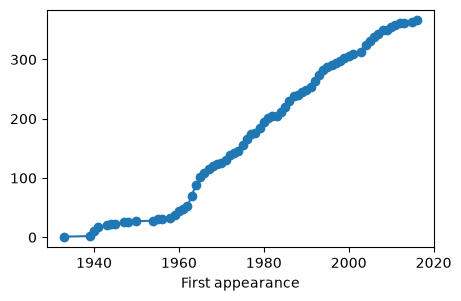

In [32]:
first_app_freq_cumulate.plot(marker='o', legend=False)
plt.show()

La frequenza cumulata corrispondente a 1970 rappresenta quindi il numero di casi nel dataset in cui l'anno di prima apparizione è minore o uguale al 1970, e dunque tale frequenza rappresenta la risposta alla terza domanda:

In [33]:
first_app_freq_cumulate.at[1970.0, 'Cumulate freq.']

np.int64(125)

Per rispondere all'ultima domanda è possibile procedere in modo analogo: la frequenza cumulata di 1980 corrisponde al numero di casi in cui l'anno di apparizione è minore o uguale a 1980, e sottraendo tale valore al numero totale di casi si ottiene la risposta:

In [34]:
first_app_freq_cumulate.iat[-1, 0] - first_app_freq_cumulate.at[1980.0, 'Cumulate freq.']

np.int64(172)

Va notato come il numero totale di casi corrisponda all'ultima delle frequenze cumulate. Infine, il concetto di frequenze cumulate si può applicare sia alle frequenze assolute, sia a quelle relative: nel secondo caso i valori ottenuti aumenteranno da 0 a 1. Nella cella seguente viene calcolata la tabella delle frequenze relative cumulate per l'anno di prima apparizione di cui vengono mostrate le ultime dieci righe.

In [35]:
first_app_relfreq_cumulate = (pd.crosstab(index=heroes_with_year['First appearance'],
                                          columns=['Cumulate freq.'],
                                          colnames=[''],
                                          normalize=True).cumsum())
first_app_relfreq_cumulate.iloc[-10:]

,Cumulate freq.
First appearance,
2006.0,0.923497
2007.0,0.937158
2008.0,0.953552
2009.0,0.956284
2010.0,0.967213
2011.0,0.980874
2012.0,0.986339
2013.0,0.989071
2015.0,0.994536


La visualizzazione in forma grafica delle frequenze relative cumulate equivale a quella precedente: l'unica differenza consiste nei valori sull'asse delle ordinate, che risulteranno ovviamente scalati sull'intervallo [0, 1]:

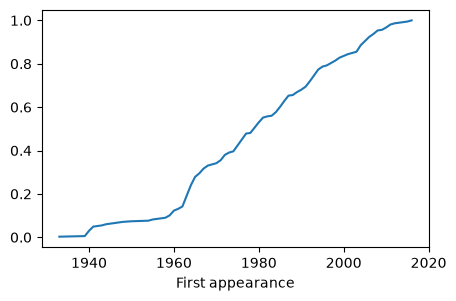

In [36]:
first_app_relfreq_cumulate.plot(legend=False)
plt.show()

Vale la pena notare come il grafico prodotto sia quello di una funzione lineare a tratti: in parole povere, si tratta di una sequenza di segmenti in cui ogni elemento ha l'estremo destro coincidente con quello sinistro del segmento successivo. Possiamo evidenziare questa proprietà effettuando uno _zoom_, per esempio tra il 1980 e il 1990:

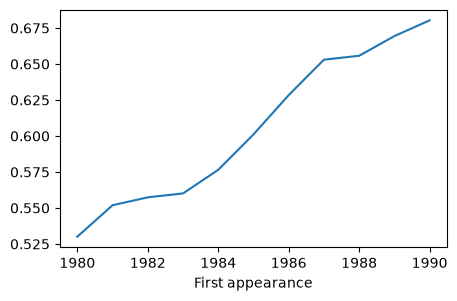

In [37]:
first_app_relfreq_cumulate.loc[1980:1990].plot(legend=False)
plt.show()

Quando i valori osservati sono di tipo numerico o ordinabile, uno strumento molto simile a quelle delle frequenze relative cumulate è rappresentato dalla _funzione cumulativa empirica_ (o _funzione di ripartizione empirica_), che dato un insieme di osservazioni $\{x_1, \dots, x_n\}$, è definita come quella funzione $\hat{F} : \mathbb{R} \mapsto [0, 1]$ tale che per ogni $x \in \mathbb{R}$ assume un valore pari alla frequenza relativa delle osservazioni che risultano essere minori o uguali a $x$. Pertanto $$\hat{F}(x) = \frac{\#\{x_i \le x\}}{n} = \frac{1}{n} \sum_{i=1}^n \mathrm{I}_{(-\infty, x_i]}(x) \tag{1}$$, 
dove $I_A : \mathbb{R} \mapsto \{0, 1\}$ indica la _funzione indicatrice_ dell'insieme $A$, che assume valore nullo in corrispondenza di tutti gli argomenti che non appartengono ad $A$ e valore unitario altrimenti, e $(- \infty, x]$ indica l'intervallo semiaperto identificato da tutti i valori reali minori o uguali a $x$. Per un generico argomento $x$, la funzione cumulativa empirica assumerà pertanto come valore la frequenza relativa cumulata del più grande tra i valori osservati $x_i \leq x$. Dunque il suo grafico sarà quello di una funzione costante a tratti. In python è presente un'implementazione della funzione cumulativa empirica nel modulo `statmodels.api`: la funzione `distributions.ECDF` accetta come input un insieme di osservazioni e restituisce la corrispondente funzione cumulativa empirica. Possiamo quindi elaborare in tal senso gli anni di prima apparizione e visualizzare il grafico corrispondente agli anni tra il 1980 e il 1990, così da poter effettuare un confronto con l'analogo grafico precedentemente generato:

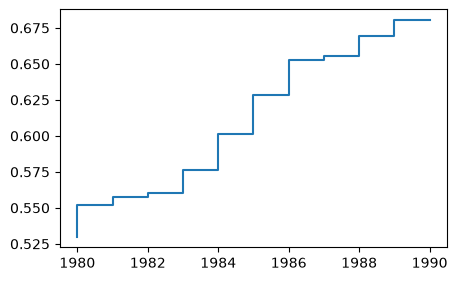

In [38]:
import statsmodels.api as sm

ecdf = sm.distributions.ECDF(heroes_with_year['First appearance'])
x = np.arange(1980, 1991)
y = ecdf(x)
plt.step(x, y)
plt.show()

<div class="alert alert-info">
    In casi come questo è meglio usare <code>plt.step</code> piuttosto che <code>plt.plot</code>, altrimenti il grafico visualizzato, pur essendo molto simile al risultato appena ottenuto, non sarebbe tecnicamente parlando quello di una funzione costante a tratti.
</div>

Va peraltro rimarcato che all'aumentare del numero di valori osservabili il grafico delle frequenze relative cumulate ottenute usando il metodo `plot` della corrispondente serie diventa indistinguibile da quello della funzione cumulativa empirica (sia che si sia utilizzato `plt.step`, sia che si sia utilizzato `plt.plot` per visualizzarlo). Per rendercene conto, possiamo visualizzare nuovamente la funzione di ripartizione empirica tenendo però conto di tutte le osservazioni per gli anni di prima apparizione.

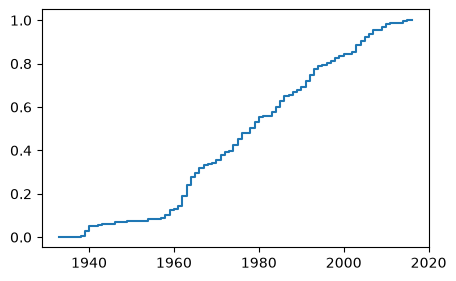

In [39]:
min_year = min(heroes_with_year['First appearance'])
max_year = max(heroes_with_year['First appearance'])
x = np.arange(min_year, max_year+1)
y = ecdf(x)
plt.step(x, y)
plt.show()

### Diagrammi di Pareto
Frequenze e frequenze cumulate di una variabile categorica possono essere considerato congiuntamente per generare un _diagramma di Pareto_ nel modo seguente: ordinando i dati per frequenza decrescente, su uno stesso sistema di riferimento in cui l'asse delle ascisse fa riferimento ai valori della variabile si sovrappongono il diagramma a barre delle frequenze e una linea spezzata che collega i valori delle frequenze cumulate. Consideriamo per esempio i colori degli occhi più frequenti del nostro dataset (definiti per comodità come i colori che occorrono con frequenza relativa superiore a 0.02).

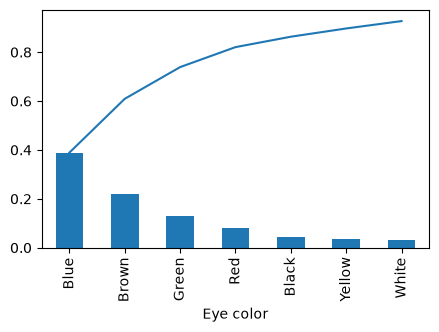

In [40]:
eye_color = heroes['Eye color']
eye_color_freq = eye_color.value_counts(normalize=True)

eye_color_freq[eye_color_freq>.02].cumsum().plot()
eye_color_freq[eye_color_freq>.02].plot.bar()
plt.show()

Ovviamente per quanto riguarda il valore più a sinistra nel diagramma (e quindi quello avente la frequenza maggiore) frequenza e frequenza cumulata coincideranno sempre.

Va notato come la linea spezzata nel precedente diagramma non arrivi all'ordinata 1, avendo considerato solo un sottoinsieme dei dati: possiamo verificarlo, oltre che visualmente, sommando le frequenze relative:

In [41]:
sum(eye_color_freq[eye_color_freq>.02])

0.9271758436944938

Se dividiamo tutte le frequenze per la somma ottenuta, apportiamo alle frequenze una correzione che fa sì che ora la loro somma sia esattamente uno (spesso si usa il termine _normalizzazione_ per indicare un'operazione di questo tipo). Il diagramma di Pareto per i valori ottenuti considerando questa correzione si estende ora fino all'ordinata unitaria.

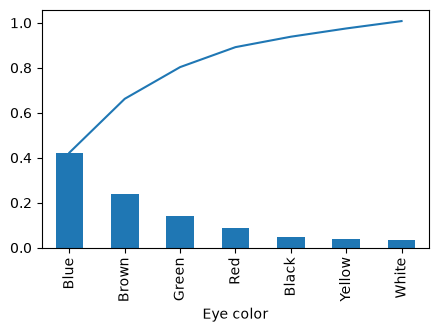

In [42]:
norm_eye_color_freq = eye_color_freq[eye_color_freq>.02]/0.92
norm_eye_color_freq.cumsum().plot()
norm_eye_color_freq.plot.bar()
plt.show()

In generale, un diagramma di Pareto permette di identificare gli elementi più rilevanti in termini di frequenze all'interno di un insieme di osservazioni, evidenziando simultaneamente il peso di ogni fattore, sia il loro peso cumulativo. Nel nostro caso, il grafico ottenuto permette per esempio di verificare a colpo d'occhio come gli occhi blu, marroni e verdi identifichino l'80% dei supereroi. Va sottolineato però che questo dato numerico è in qualche modo influenzato dalla scelta di avere escluso tutti i colori con una frequenza relativa minore di 0.02. Implementiamo una funzione `my_pareto` che permette di impostare la soglia sulle frequenze e rigeneriamo il grafico, stavolta considerando tutti i dati.

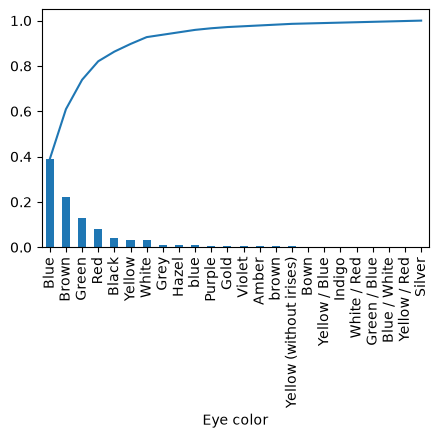

In [43]:
def my_pareto(data, threshold=0.02, renormalize=False):
    freq = data.value_counts(normalize=True)
    freq = freq[freq > threshold]
    if renormalize:
        freq = freq / sum(freq)
    freq.cumsum().plot()
    freq.plot.bar()

my_pareto(heroes['Eye color'],threshold= 0)

Notate come il grafico ottenuto sia particolarmente poco leggibile, essendo popolato nella metà destra da colori che, presi singolarmente, hanno una frequenza non rilevabile nel diagramma a barre. Considerate cumulativamente, queste frequenze hanno però un effetto sul grafico: in effetti, se vogliamo considerare l'80% dei dati è necessario includere anche il colore rosso. La definizione della funzione `my_pareto` evita in effetti di correggere i dati, a meno che non venga specificamente indicato tramite l'argomento `renormalize`, così da ottenere un grafico più preciso.

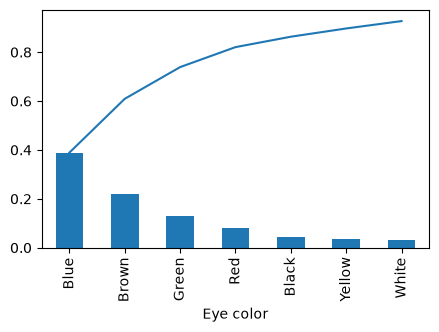

In [44]:
my_pareto(heroes['Eye color'], threshold=0.015)

## Frequenze congiunte e marginali
Spesso è utile analizzare un insieme di osservazioni prendendo in considerazione due caratteri al posto di uno, per esempio per vedere se i valori di tali caratteri tendano a essere più o meno collegati tra loro tramite una relazione. Il concetto di frequenza si specializza in questo caso andando a contare il numero di osservazioni in cui i due caratteri considerati assumono due determinati valori, ottenendo la cosiddetta _frequenza congiunta assoluta_ (o equivalentemente la _frequenza congiunta relativa_ nel caso in cui si calcolasse la frazione di osservazioni e non il suo numero). Nel caso in cui i possibili valori osservabili non siano parecchi, è possibile visualizzare queste frequenze tramite una _tabella delle frequenze congiunte_ (detta anche _tabella di contingenza_), ottenuta estendendo il concetto di tabella delle frequenze precedentemente introdotto: ora le righe della tabella corrisponderanno ai possibili valori di uno dei caratteri considerati, le sue colonne corrisponderanno ai valori del rimanente carattere e gli elementi della tabella conterranno le frequenze congiunte (assolute o relative). La funzione `pd.crosstab` può essere utilizzata anche per produrre questo tipo di tabella: basta indicare le serie corrispondenti ai caratteri considerati come valori degli argomenti `index` e `columns`

In [46]:
# importante: rimuovere i duplicati!
heroes = heroes[~heroes.index.duplicated()]

In [47]:
int_gender_freq = pd.crosstab(index=heroes['Intelligence'],
                              columns=heroes['Gender'])
int_gender_freq

Gender,F,M
Intelligence,,
average,37,99
good,75,163
high,27,110
low,0,13
moderate,21,37


L'ordine delle righe può essere modificato nello stesso modo visto per le tabelle delle frequenze: per modificare la tabella in modo che risulti ordinata per i valori di intelligenza piuttosto che in modo alfabetico sarà quindi sufficiente utilizzare il metodo `reindex`

In [48]:
int_gender_freq = int_gender_freq.reindex(['low', 'moderate', 'average',
                                           'good', 'high'])
int_gender_freq

Gender,F,M
Intelligence,,
low,0,13
moderate,21,37
average,37,99
good,75,163
high,27,110


Siccome `crosstab` produce dei dataframe, per riordinare le colonne è sufficiente accedere alla tabella tramite `loc` e specificando come secondo argomento una lista dei valori nell'ordine desiderato:

In [49]:
int_gender_freq.loc[:, ['M', 'F']]

Gender,M,F
Intelligence,,
low,13,0
moderate,37,21
average,99,37
good,163,75
high,110,27


In modo analogo è possibile visualizzare solo alcune righe oppure solo alcune colonne della tabella, come nella cella seguente:

In [50]:
int_gender_freq.loc['moderate':'good', :]

Gender,F,M
Intelligence,,
moderate,21,37
average,37,99
good,75,163


<div class="alert alert-warning">
    Va notato che quella appena ottenuta non è più una tabella delle frequenze, in quanto non fa riferimento a tutti i possibili valori in gioco
</div>

Sempre ipotizzando che il numero di valori osservabili non sia troppo elevato, la visualizzazione grafica delle frequenze congiunte può essere effettuata estendendo il concetto di diagramma a barre in modo che visualizzi due caratteri al posto di uno, _raggruppando_ le barre che fanno riferimento a uno stesso valore per uno dei caratteri, e _colorandole_ in funzione del valore che queste assumono per l'altro carattere in gioco. Il posizionamento delle barre viene normalmente fatto in due possibili modi:
- invocando il metodo `plot.bar` invocato sulla tabella, in modo che le barre relative a uno stesso valore risultino _affiancate_

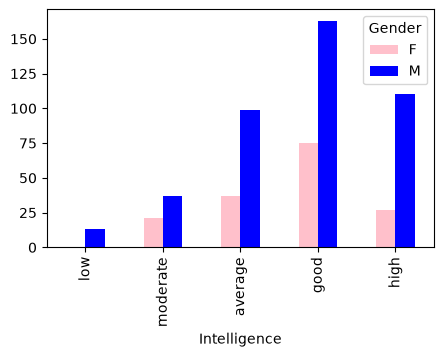

In [51]:
int_gender_freq.plot.bar(color=['pink', 'blue'])
plt.show()

- specificando ulteriormente il valore `True` per l'argomento `stacked`, in modo da _sovrapporre_ le barre che si riferiscono a uno stesso valore:

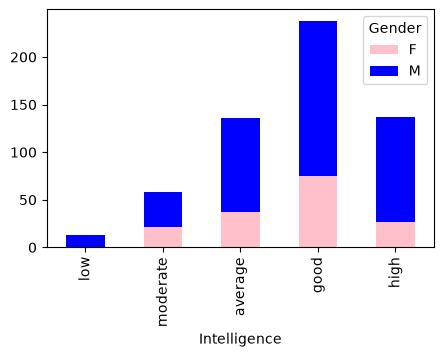

In [52]:
int_gender_freq.plot.bar(color=['pink', 'blue'], stacked=True)
plt.show()

Nel caso in cui si volessero calcolare le frequenze congiunte e almeno uno dei caratteri fosse numerico, si rischierebbe di ricadere nello stesso problema descritto quando abbiamo parla5to degli istogrammi: si consideri per esempio il tentativo di calcolare le frequenze congiunte di peso e genere:

In [53]:
pd.crosstab(index=heroes['Weight'], columns=[heroes['Gender']]).iloc[:10, :]

Gender,F,M
Weight,,
2.34,0,1
4.82,0,1
9.79,0,1
14.67,0,1
16.20,0,1
17.01,0,1
18.11,0,1
18.45,0,1
19.00,0,1


Essenzialmente in ogni riga c'è un valore nullo e uno unitario, semplicemente perchè succede quasi sempre che un particolare valore del peso specificato fino a decigrammi occorra un'unica volta nelle osservazioni. È quindi opportuno raggruppare assieme pesi "vicini" tra loro. Ciò viene fatto utilizzando la funzione `pd.cut`, che converte una serie di valori numerici in una serie qualitativa i cui valori possibili sono gli intervalli di una partizione aventi per estremi i valori specificati in corrispondenza dell'argomento `bins`. Considerando questa nuova serie è possibile generare una tabella delle frequenze congiunte più significativa

In [54]:
pd.cut(heroes['Weight'], bins=[30, 50, 80, 100, 200, 500, 1000])

Name
A-Bomb         (200.0, 500.0]
Abraxas                   NaN
Abomination    (200.0, 500.0]
Adam Monroe               NaN
Agent 13         (50.0, 80.0]
                    ...      
Alan Scott      (80.0, 100.0]
Amazo          (100.0, 200.0]
Ant-Man        (100.0, 200.0]
Ajax            (80.0, 100.0]
Alex Mercer               NaN
Name: Weight, Length: 717, dtype: category
Categories (6, interval[int64, right]): [(30, 50] < (50, 80] < (80, 100] < (100, 200] < (200, 500] < (500, 1000]]

In [55]:
pd.crosstab(index=pd.cut(heroes['Weight'],
                         bins=[30, 50, 80, 100, 200, 500, 1000]),
            columns=[heroes['Gender']])

Gender,F,M
Weight,,
"(30, 50]",4,4
"(50, 80]",113,86
"(80, 100]",5,109
"(100, 200]",11,83
"(200, 500]",5,38
"(500, 1000]",1,5


Le impostazioni predefinite di `pd.cut` fanno riferimento a intervalli aperti a sinistra e chiusi a destra, ma è possibile invertire l'apertura e la chiusura degli estremi utilizzando l'argomento opzionale `right`:

In [56]:
pd.crosstab(index=pd.cut(heroes['Weight'], bins=[30, 50, 80, 100, 200, 500, 1000],
                         right=False),
            columns=[heroes['Gender']])

Gender,F,M
Weight,,
"[30, 50)",4,4
"[50, 80)",113,86
"[80, 100)",5,109
"[100, 200)",11,83
"[200, 500)",5,38
"[500, 1000)",1,5


Quando si genera una tabella di frequenze congiunte, è possibile specificare il valore `True` per l'argomento `margins` al fine di raggiungere una riga e una colonna che contengono i totali (calcolati rispettivamente sulle singole colonne e sulle singole righe). I valori ivi indicati prendono il nome di _frequenze marginali_, e corrispondono alle frequenze del carattere corrispondente. Per esempio, rigenerando la tabella delle frequenze congiunte di livello di intelligenza e genere con le colonne dei totali, 

In [57]:
pd.crosstab(index=heroes['Intelligence'],
            columns=heroes['Gender'], margins=True)

Gender,F,M,All
Intelligence,,,
average,37,99,136
good,75,163,238
high,27,110,137
low,0,13,13
moderate,21,37,58
All,160,422,582


la colonna `all` conterrà le frequenze assolute per il carattere Intelligence, e parimenti la riga `All` elencherà le frequenze assolute per il genere (escludendo ovviamente in entrambi i casi l'ultimo elemento che corrisponde al numero totale di osservazioni).

Le frequenze congiunte a cui abbiamo fatto riferimento negli esempi visti finora erano frequenze assolute, ma è immediato estendere tale concetto a quello delle _frequenze congiunte relative_. Queste si possono calcolare dividendo le frequenze assolute per il numero totale di osservazioni, oppure utilizzando come in precedenza il parametro `normalize` in `pd.crosstab`, che però ora ha diversi valori possibili:
- specificando `'all'` vengono effettivamente calcolate le frequenze relative

In [58]:
pd.crosstab(index=heroes['Intelligence'],
            columns=heroes['Gender'],
            margins=True,
            normalize='all')

Gender,F,M,All
Intelligence,,,
average,0.063574,0.170103,0.233677
good,0.128866,0.280069,0.408935
high,0.046392,0.189003,0.235395
low,0.000000,0.022337,0.022337
moderate,0.036082,0.063574,0.099656
All,0.274914,0.725086,1.000000


- usando `'index'` si otterrà una tabella in cui i valori su ogni riga sommano a 1

In [59]:
pd.crosstab(index=heroes['Intelligence'],
            columns=heroes['Gender'],
            margins=True,
            normalize='index')

Gender,F,M
Intelligence,,
average,0.272059,0.727941
good,0.315126,0.684874
high,0.197080,0.802920
low,0.000000,1.000000
moderate,0.362069,0.637931
All,0.274914,0.725086


- indicando invece `'columns'` viene generata una tabella in cui tutte le colonne sommano al valore unitario

In [60]:
pd.crosstab(index=heroes['Intelligence'],
            columns=heroes['Gender'],
            margins=True,
            normalize='columns')

Gender,F,M,All
Intelligence,,,
average,0.23125,0.234597,0.233677
good,0.46875,0.386256,0.408935
high,0.16875,0.260664,0.235395
low,0.00000,0.030806,0.022337
moderate,0.13125,0.087678,0.099656


La normalizzazione per colonne permette di ottenere una tabella che contiene le frequenze relative di due sotto-popolazioni come nel caso precedentemente visto, relativo alla forza di supereroi e supereroine.
Invocando `plot` o `plot.bar` su questa tabella si ottiene in modo semplice un grafico che permette di confrontare visualmente tali frequenze

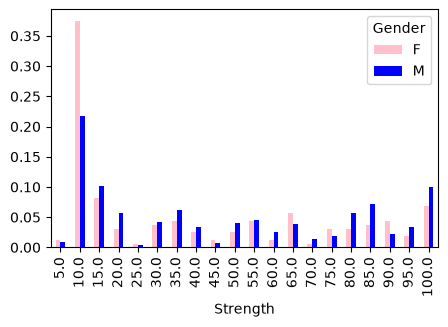

In [61]:
pd.crosstab(index=heroes['Strength'],
            columns=[heroes['Gender']],
            normalize='columns').plot.bar(color=['pink', 'blue'],
                                          stacked=False)
plt.show()

Abbiamo visto in una lezione precedente come generare direttamente un grafico di una serie senza elaborarla (calcolando per esempio le sue frequenze) produce un risultato che non è normalmente informativo. Le cose sono diverse quando si considerano congiuntamente due serie con un medesimo indice: in tal caso per ogni elemento di questo indice (e dunque per ogni osservazione), i valori delle due serie possono essere utilizzati per individuare le coordinate di un punto nel piano. Visualizzando i punti corrispondenti a tutte le osservazioni si ottiene un _diagramma di dispersione_ (o _scatter plot_). In pandas questo tipo di grafico si genera invocando il metodo `plot.scatter` sul _dataframe_ che contiene le osservazioni, indicando come argomenti i nomi dei caratteri che devono essere considerati (il primo dei quali verrà visualizzato sull'asse delle ascisse, usando invece quello delle ordinate per il secondo). Per esempio nella cella seguente viene visualizzato il diagramma di dispersione dei caratteri relativi ad altezza e peso dei supereroi di genere maschile

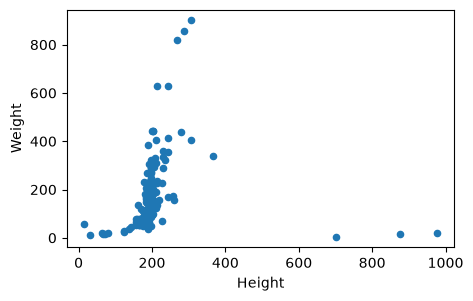

In [62]:
heroes[heroes['Gender']=='M'].plot.scatter('Height', 'Weight')
plt.show()

I diagrammi di dispersione permettono di valutare visivamente se esistano delle relazioni che legano i due caratteri visualizzati. Per esempio nel grafico precedente si nota come tendenzialmente a un valore alto del peso corrisponda un valore alto per l'altezza e viceversa. Volendo è possibile aggiungere al grafico una retta che metta in evidenza tale tipo di relazione:

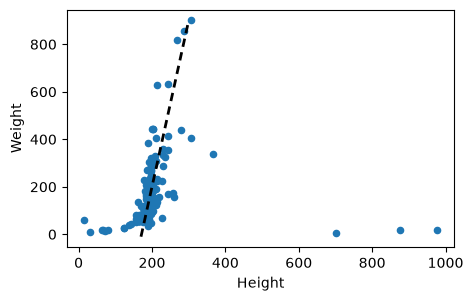

In [63]:
heroes[heroes['Gender']=='M'].plot.scatter('Height', 'Weight')

trend = lambda x: -1200 + x * 7
x_range = [170, 300]
line, = plt.plot(x_range, list(map(trend, x_range)), color='black')
line.set_dashes([3, 2])
line.set_linewidth(2)
plt.show()

Idropnan questo caso la retta è stata posizionata "a mano": esistono metodi che ci permettono di determinarla in funzione delle osservazioni. Per il momento mettiamo in evidenza la possibilità di definire in modo formale una retta scelta in modo da minimizzare una sua distanza da tutti i punti, utilizzando il cosiddetto _metodo dei minimi quadrati_. La cella seguente mostra come determinate tale retta, avendo cura di lavorare su una copia del _dataframe_ sulla quale invocare il metodo `dropna` che elimina le righe in cui è presente almeno un valore mancante

C:\Users\Yeyian Gaming\ambiente_jupyter\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


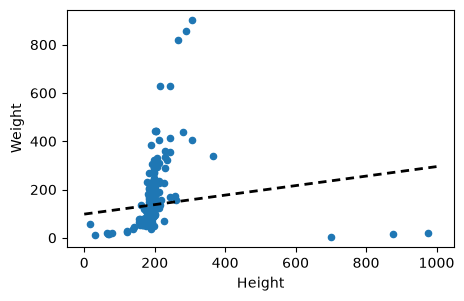

In [65]:
from sklearn import linear_model

regr = linear_model.LinearRegression()

heroes_with_data = heroes[heroes['Gender']=='M'].copy().dropna()

X = heroes_with_data.loc[:, ['Height']]
Y = heroes_with_data['Weight']

regr.fit(X, Y)

heroes[heroes['Gender']=='M'].plot.scatter('Height', 'Weight')

line, = plt.plot([0, 1000], regr.predict([[0], [1000]]), color='black')
line.set_dashes([3, 2])
line.set_linewidth(2)

plt.show()

Notiamo come la presenza dei tre valori estremi nella parte destra del grafico fa sì che la retta ottenuta sia sensibilmente diversa da quella tracciata a mano. Le cose cambiano se non si considerano questi tre valori

C:\Users\Yeyian Gaming\ambiente_jupyter\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


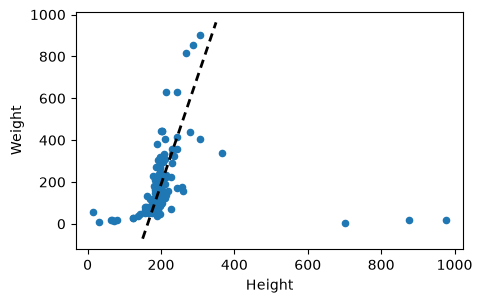

In [66]:
heroes_with_data = heroes_with_data[heroes_with_data['Height']<300]

X = heroes_with_data.loc[:, ['Height']]
Y = heroes_with_data['Weight']

regr.fit(X, Y)

heroes[heroes['Gender']=='M'].plot.scatter('Height', 'Weight')

line, = plt.plot([150, 350], regr.predict([[150], [350]]), color='black')
line.set_dashes([3, 2])
line.set_linewidth(2)

plt.show()

Va infine notato che le relazioni tra due caratteri non necessariamente hanno una forma lineare, ma approfondire questo aspetto esula dal carattere introduttivo di questo corso

In [67]:
male_heroes = heroes_with_data[heroes_with_data['Gender']=='M']
male_heroes['Height'].cov(male_heroes['Weight'])

np.float64(1834.8391752525254)

In [68]:
male_heroes['Height'].corr(male_heroes['Weight'])

np.float64(0.827061637306922)